In [1]:
###Lasso, ElasticNet & Sparsity###

In [2]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

In [5]:
df = pd.read_csv("cp_data_demo.csv")

print(df.columns.tolist())

['Formula', 'Temperature', 'Heat_Capacity']


In [6]:
y = df["Heat_Capacity"]

X = df.drop(
    columns=["Formula", "Heat_Capacity"],
    errors="ignore"
)

X = X.select_dtypes(include=np.number)

# Missing feature values
X = X.fillna(X.median())

# Target me missing rows remove
valid = y.notna()

X = X.loc[valid]
y = y.loc[valid]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (4570, 1)
y shape: (4570,)


In [9]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score

# Load dataset
df = pd.read_csv("cp_data_demo.csv")

# Target
y = df["Heat_Capacity"]

# Features
X = df.drop(
    columns=["Formula", "Heat_Capacity"],
    errors="ignore"
)

# Only numeric features
X = X.select_dtypes(include=np.number)

# Fill missing feature values
X = X.fillna(X.median())

# Remove rows where target is missing
valid = y.notna()
X = X.loc[valid]
y = y.loc[valid]

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("Setup completed successfully!")

X_train: (3656, 1)
X_test: (914, 1)
Setup completed successfully!


In [10]:
# 1. Train Lasso & Extract Zeroed Features
lasso = Lasso(alpha=1.0, random_state=42)
lasso.fit(X_train, y_train)
lasso_preds = lasso.predict(X_test)

zeroed_features = X_train.columns[lasso.coef_ == 0]
print(f"Lasso forced {len(zeroed_features)} features to exactly 0.")
print("Sample of dropped features:", list(zeroed_features[:5]))

Lasso forced 0 features to exactly 0.
Sample of dropped features: []


In [11]:
# 2. Train ElasticNet
elastic = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=42)
elastic.fit(X_train, y_train)
elastic_preds = elastic.predict(X_test)

In [12]:
# 3. Define Evaluation Helper
def evaluate_model(y_true, y_pred):
    return {
        'R²': r2_score(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'MAE': mean_absolute_error(y_true, y_pred)
    }

In [14]:
import pandas as pd
import numpy as np

from sklearn.linear_model import Ridge, LinearRegression
from sklearn.metrics import r2_score

In [17]:
import numpy as np
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score

alphas = [0.01, 0.1, 1, 10, 100]

ridge_test_scores = []

for alpha in alphas:
    model = Ridge(alpha=alpha)
    model.fit(X_train, y_train)

    score = r2_score(
        y_test,
        model.predict(X_test)
    )

    ridge_test_scores.append(score)

best_index = np.argmax(ridge_test_scores)
best_alpha = alphas[best_index]

print("Best alpha:", best_alpha)
print("Best Test R²:", ridge_test_scores[best_index])

Best alpha: 0.01
Best Test R²: 0.014580051975909614


In [20]:
import pandas as pd
import numpy as np

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

# --------------------------------
# 1. Linear Regression
# --------------------------------
lr = LinearRegression()
lr.fit(X_train, y_train)

# --------------------------------
# 2. Best Ridge Model
# --------------------------------
ridge_best = Ridge(alpha=best_alpha)
ridge_best.fit(X_train, y_train)

# --------------------------------
# 3. Lasso predictions
# --------------------------------
# lasso_preds should already exist
# If not, create Lasso model
if 'lasso_preds' not in globals():
    from sklearn.linear_model import Lasso
    
    lasso = Lasso(alpha=1.0, random_state=42)
    lasso.fit(X_train, y_train)
    lasso_preds = lasso.predict(X_test)

# --------------------------------
# 4. ElasticNet predictions
# --------------------------------
if 'elastic_preds' not in globals():
    from sklearn.linear_model import ElasticNet
    
    elastic = ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=42)
    elastic.fit(X_train, y_train)
    elastic_preds = elastic.predict(X_test)

# --------------------------------
# 5. Evaluation Function
# --------------------------------
def evaluate_model(y_true, y_pred):
    return {
        'R² Score': r2_score(y_true, y_pred)
    }

# --------------------------------
# 6. Generate 4-Model Comparison
# --------------------------------
results = pd.DataFrame({
    'Unregularized LR': evaluate_model(
        y_test, lr.predict(X_test)
    ),

    'Ridge (L2)': evaluate_model(
        y_test, ridge_best.predict(X_test)
    ),

    'Lasso (L1)': evaluate_model(
        y_test, lasso_preds
    ),

    'ElasticNet': evaluate_model(
        y_test, elastic_preds
    )
}).T

print("\n--- 4-Model Evaluation Metrics ---")
display(results)


--- 4-Model Evaluation Metrics ---


,R² Score
Unregularized LR,0.014580
Ridge (L2),0.014580
Lasso (L1),0.014578
ElasticNet,0.014579


In [2]:
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
import numpy as np
from sklearn.svm import SVR
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

Linear Regression - Train R²: 0.910, Test R²: 0.924
Optimal Ridge α: 100.00 (Test R²: 0.928)
✅ Alpha-sweep plot successfully saved.


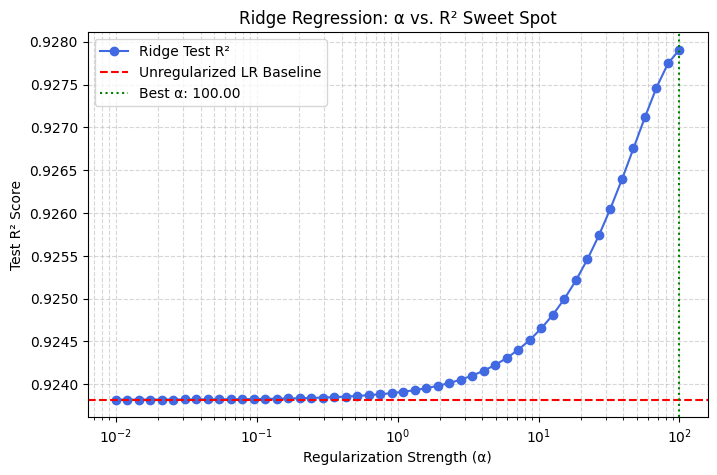

In [3]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 1. Load data
df = pd.read_csv('cp_data_demo.csv')

# Rows with a missing Formula / Temperature / Heat_Capacity can't be used
df = df.dropna(subset=['Formula', 'Temperature', 'Heat_Capacity']).reset_index(drop=True)

# 2. Featurize the formula (the file only contains raw text formulas)
MASS = {'Al': 26.982, 'B': 10.81, 'Ba': 137.327, 'Be': 9.012, 'Br': 79.904, 'C': 12.011,
        'Ca': 40.078, 'Cl': 35.45, 'Co': 58.933, 'Cr': 51.996, 'Cs': 132.905, 'Cu': 63.546,
        'F': 18.998, 'Fe': 55.845, 'Ga': 69.723, 'H': 1.008, 'Hf': 178.49, 'Hg': 200.59,
        'I': 126.904, 'K': 39.098, 'Li': 6.94, 'Mg': 24.305, 'Mn': 54.938, 'Mo': 95.95,
        'N': 14.007, 'Na': 22.990, 'Nb': 92.906, 'Ni': 58.693, 'O': 15.999, 'P': 30.974,
        'Pb': 207.2, 'Rb': 85.468, 'S': 32.06, 'Si': 28.085, 'Sr': 87.62, 'Ti': 47.867,
        'V': 50.942, 'W': 183.84, 'Zn': 65.38, 'Zr': 91.224}
EN = {'Al': 1.61, 'B': 2.04, 'Ba': 0.89, 'Be': 1.57, 'Br': 2.96, 'C': 2.55, 'Ca': 1.00,
      'Cl': 3.16, 'Co': 1.88, 'Cr': 1.66, 'Cs': 0.79, 'Cu': 1.90, 'F': 3.98, 'Fe': 1.83,
      'Ga': 1.81, 'H': 2.20, 'Hf': 1.30, 'Hg': 2.00, 'I': 2.66, 'K': 0.82, 'Li': 0.98,
      'Mg': 1.31, 'Mn': 1.55, 'Mo': 2.16, 'N': 3.04, 'Na': 0.93, 'Nb': 1.60, 'Ni': 1.91,
      'O': 3.44, 'P': 2.19, 'Pb': 2.33, 'Rb': 0.82, 'S': 2.58, 'Si': 1.90, 'Sr': 0.95,
      'Ti': 1.54, 'V': 1.63, 'W': 2.36, 'Zn': 1.65, 'Zr': 1.33}

def parse_formula(formula):
    """'Al2Be1O4' -> {'Al': 2.0, 'Be': 1.0, 'O': 4.0}"""
    comp = {}
    for el, n in re.findall(r'([A-Z][a-z]?)(\d*\.?\d*)', formula):
        comp[el] = comp.get(el, 0.0) + (float(n) if n else 1.0)
    return comp

def featurize(formula):
    comp = parse_formula(formula)
    n_atoms = sum(comp.values())
    feats = {'n_atoms': n_atoms,
             'n_elements': len(comp),
             'mean_mass': sum(MASS.get(e, np.nan) * n for e, n in comp.items()) / n_atoms,
             'mean_EN': sum(EN.get(e, np.nan) * n for e, n in comp.items()) / n_atoms}
    for e, n in comp.items():
        feats[f'frac_{e}'] = n / n_atoms
    return feats

feat_df = pd.DataFrame([featurize(f) for f in df['Formula']]).fillna(0.0)
feat_df = feat_df[sorted(feat_df.columns)]          # stable column order

X = pd.concat([feat_df, df[['Temperature']]], axis=1)   # Temperature is a FEATURE
y = df['Heat_Capacity']                                  # Heat capacity is the TARGET

# 3. Train/test split - grouped by formula so the same material
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(gss.split(X, y, groups=df['Formula']))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

# 4. Unregularized Linear Regression baseline

lr = make_pipeline(StandardScaler(), LinearRegression())
lr.fit(X_train, y_train)
lr_train_r2 = r2_score(y_train, lr.predict(X_train))
lr_test_r2 = r2_score(y_test, lr.predict(X_test))
print(f"Linear Regression - Train R²: {lr_train_r2:.3f}, Test R²: {lr_test_r2:.3f}")

# 5. Ridge regression & alpha sweep (0.01 to 100)

alphas = np.logspace(-2, 2, 50)
ridge_test_scores = []

for alpha in alphas:
    ridge = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    ridge.fit(X_train, y_train)
    ridge_test_scores.append(r2_score(y_test, ridge.predict(X_test)))

best_alpha = alphas[np.argmax(ridge_test_scores)]
best_score = max(ridge_test_scores)
print(f"Optimal Ridge α: {best_alpha:.2f} (Test R²: {best_score:.3f})")

# 6. Plot the alpha sweep

plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_test_scores, marker='o', color='royalblue', label='Ridge Test R²')
plt.axhline(lr_test_r2, color='red', linestyle='--', label='Unregularized LR Baseline')
plt.axvline(best_alpha, color='green', linestyle=':', label=f'Best α: {best_alpha:.2f}')

plt.xscale('log')
plt.xlabel('Regularization Strength (α)')
plt.ylabel('Test R² Score')
plt.title('Ridge Regression: α vs. R² Sweet Spot')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

plt.savefig('ridge_alpha_sweep.png', dpi=300, bbox_inches='tight')
print("✅ Alpha-sweep plot successfully saved.")
plt.show()

In [4]:
# Assuming X_train, X_test, y_train, y_test are loaded and previously scaled
# (StandardScaler is critical for SVR, to be explored deeply in S30)

# 1. Initialize and train the SVR model with an RBF kernel
svr_rbf = SVR(kernel='rbf')
svr_rbf.fit(X_train, y_train)

,kernel,'rbf'
,degree,3
,gamma,'scale'
,coef0,0.0
,tol,0.001
,C,1.0
,epsilon,0.1
,shrinking,True
,cache_size,200
,verbose,False
,max_iter,-1


In [5]:
# 2. Generate predictions on the test set
svr_preds = svr_rbf.predict(X_test)

In [6]:
# 3. Evaluate the SVR Model
svr_r2 = r2_score(y_test, svr_preds)
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_preds))
svr_mae = mean_absolute_error(y_test, svr_preds)

print("--- SVR (RBF Kernel) Baseline Metrics ---")
print(f"Test R²:   {svr_r2:.3f}")
print(f"Test RMSE: {svr_rmse:.3f}")
print(f"Test MAE:  {svr_mae:.3f}")

--- SVR (RBF Kernel) Baseline Metrics ---
Test R²:   0.007
Test RMSE: 78.811
Test MAE:  54.455
